# 01e - DINOv2 ViT-S/14 with a ViT-appropriate learning rate (extra experiment, 15 epochs like every other model)
**Why a different learning rate:** in the shared recipe (backbone 1e-4 for every layer) DINOv2 trained slowly and was still improving at epoch 15. Pretrained ViTs are sensitive to large steps, especially in their early layers.
**Settings used here:** AdamW, top-block learning rate **5e-5** (a common ViT fine-tuning value), **layer-wise decay 0.75** (each lower block gets 0.75x the rate of the block above), classifier head 10x the top rate (5e-4), **15 epochs (same as all other models)**, same warm-up, cosine schedule, augmentation, batch size, weight decay and split as the other models.
The effective rates per layer are printed when training starts.
This is an ADDITIONAL experiment: the controlled comparison (01a-01d) is unchanged and `compare.py` lists this run in a separate table. Choose between DINOv2 variants by VALIDATION macro-F1, not by test. Results: `results/dinov2_vit_s14_tuned/`.

In [ ]:
ARCH = "dinov2_vit_s14"
MODEL = "dinov2_vit_s14_tuned"   # tag of this variant (checkpoint + results folder)
from google.colab import drive; drive.mount("/content/drive")
import subprocess, sys, os
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "scikit-learn", "scipy", "tabulate"], check=True)
os.makedirs("/content/plant_pipeline", exist_ok=True); os.makedirs("/content/data_v3", exist_ok=True)

Mounted at /content/drive


In [ ]:
# ---- code bundle: all pipeline .py files (config, build_dataset, train, evaluate, report, compare, predict ...) ----
# Writing them here guarantees this notebook never runs a stale or half-patched copy from Drive. Readable copies: 00b notebook / plant_pipeline.zip.
import base64, io, zipfile, os, shutil
B64 = (
    "..."
    "9OUEsFBgAAAAAOAA4AGgMAAKlRAAAAAA=="
)
os.makedirs("/content/plant_pipeline", exist_ok=True)
zipfile.ZipFile(io.BytesIO(base64.b64decode(B64))).extractall("/content/plant_pipeline")
os.makedirs("/content/drive/MyDrive/plant-disease-v3/code", exist_ok=True)
for f in os.listdir("/content/plant_pipeline"):
    if f.endswith(".py"): shutil.copy("/content/plant_pipeline/" + f, "/content/drive/MyDrive/plant-disease-v3/code/" + f)
print("code version:", open("/content/plant_pipeline/VERSION").read(), "|", sorted(f for f in os.listdir("/content/plant_pipeline") if f.endswith(".py")))

code version: v3-full-report | ['audit_sources.py', 'build_dataset.py', 'common.py', 'compare.py', 'config.py', 'evaluate.py', 'ood_utils.py', 'optim_utils.py', 'predict.py', 'report.py', 'sources.py', 'splits.py', 'train.py']


In [ ]:
%cd /content/plant_pipeline

/content/plant_pipeline


In [ ]:
TAR = "/content/drive/MyDrive/plant-disease-v3/data_v3.tar"
if not os.path.exists("/content/data_v3/manifest.csv"):
    if not os.path.exists(TAR): raise FileNotFoundError("data_v3.tar not found on Drive -> run 00_build_dataset_v3.ipynb first")
    subprocess.run(["tar", "-xf", TAR, "-C", "/content/data_v3"], check=True)
import pandas as pd
m = pd.read_csv("/content/data_v3/manifest.csv"); print("images:", len(m), "| per split:", m.split.value_counts().to_dict(), "| classes:", m.label.nunique())
import torch; assert torch.cuda.is_available(), "Runtime > Change runtime type > T4 GPU"
!python -c "import config as C; print('shared settings for ALL models:', C.TRAIN); print('common kwargs:', C.COMMON_KW)"

images: 11027 | per split: {'train': 7745, 'val': 1645, 'test': 1637} | classes: 10
shared settings for ALL models: {'epochs': 15, 'batch': 32, 'weight_decay': 0.05, 'head_mult': 10, 'warmup_epochs': 1, 'label_smoothing': 0.1, 'lr': 0.0001, 'field_boost': 3.0}
common kwargs: {'drop_rate': 0.2, 'drop_path_rate': 0.1}


## Train (top-block lr 5e-5, layer-wise decay 0.75, 15 epochs)

In [ ]:
!python train.py --model {ARCH} --lr 5e-5 --epochs 15 --llrd 0.75 --suffix _tuned

train 7745 | val 1645 | classes 10 | md5 8fc9241c | tag dinov2_vit_s14_tuned | recipe: epochs=15, lr=5e-05, llrd=0.75

model.safetensors: downloading bytes:  47% 41.8M/88.2M [00:01<00:00, 58.3MB/s, 2.41MB/s  ]
model.safetensors: reconstructing file:  57% 50.3M/88.2M [00:01<00:00, 45.6MB/s]
model.safetensors: downloading bytes:  70% 62.1M/88.2M [00:01<00:00, 72.5MB/s, 4.87MB/s  ]
model.safetensors: downloading bytes:  89% 78.7M/88.2M [00:01<00:00, 75.9MB/s, 6.70MB/s  ]
model.safetensors: downloading bytes: 100% 83.7M/83.7M [00:01<00:00, 54.6MB/s, 7.84MB/s  ]
model.safetensors: reconstructing file: 100% 88.2M/88.2M [00:01<00:00, 57.6MB/s, 8.32MB/s  ]
layer-wise learning rates (0 = embeddings, 1..12 = blocks, 13 = final norm): {0: '1.2e-06', 1: '1.6e-06', 2: '2.1e-06', 3: '2.8e-06', 4: '3.8e-06', 5: '5.0e-06', 6: '6.7e-06', 7: '8.9e-06', 8: '1.2e-05', 9: '1.6e-05', 10: '2.1e-05', 11: '2.8e-05', 12: '3.8e-05', 13: '5.0e-05', 'head': '5.0e-04'}
[dinov2_vit_s14 lr=5e-05] ep 01/15   81s | tra

## Evaluate: whole report, saved to Drive

In [ ]:
!python evaluate.py --tag {MODEL}

 FULL EVALUATION REPORT - dinov2_vit_s14_tuned
architecture dinov2_vit_s14 | recipe: epochs=15, lr=5e-05, llrd=0.75 | 21.6M params | lr 5e-05 | 15 epochs | best epoch (val macro-F1) = 13
split sizes: train 7745 | val 1645 | test 1637 (test = PlantVillage-test + PlantDoc-test pooled)

HEADLINE (pooled test): accuracy 98.72%  (95% bootstrap CI 98.11-99.27) | macro-F1 98.47% | macro ROC-AUC 0.99873
CALIBRATION (test): ECE 0.1013 -> 0.0072 after temperature scaling (T=0.63, fitted on validation); lower ECE = confidence matches accuracy
REJECT THRESHOLD (deployment only, from validation): Mahalanobis distance <= 1601.2 keeps 95% of validation images

 1. OVERALL METRICS  (clean images, no augmentation; checkpoint = best validation macro-F1)

            n  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  cohen_kappa     mcc  log_loss  auc_macro_ovr  auc_micro
train  7745.0    0.9943           0.9918        0.9926    0.9922       0.9943       0.9936  0.9936    0.1279         0

## Plots

Overall metrics (clean images, no augmentation):


,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,cohen_kappa,mcc,log_loss,auc_macro_ovr,auc_micro
train,7745.0,0.9943,0.9918,0.9926,0.9922,0.9943,0.9936,0.9936,0.1279,0.9996,0.9995
val,1645.0,0.9836,0.9777,0.9801,0.9788,0.9837,0.9816,0.9816,0.1678,0.9968,0.9961
test,1637.0,0.9872,0.9836,0.9860,0.9847,0.9872,0.9856,0.9856,0.1545,0.9987,0.9980



TRAIN vs VALIDATION per epoch: loss, accuracy, precision, recall, F1, learning rate


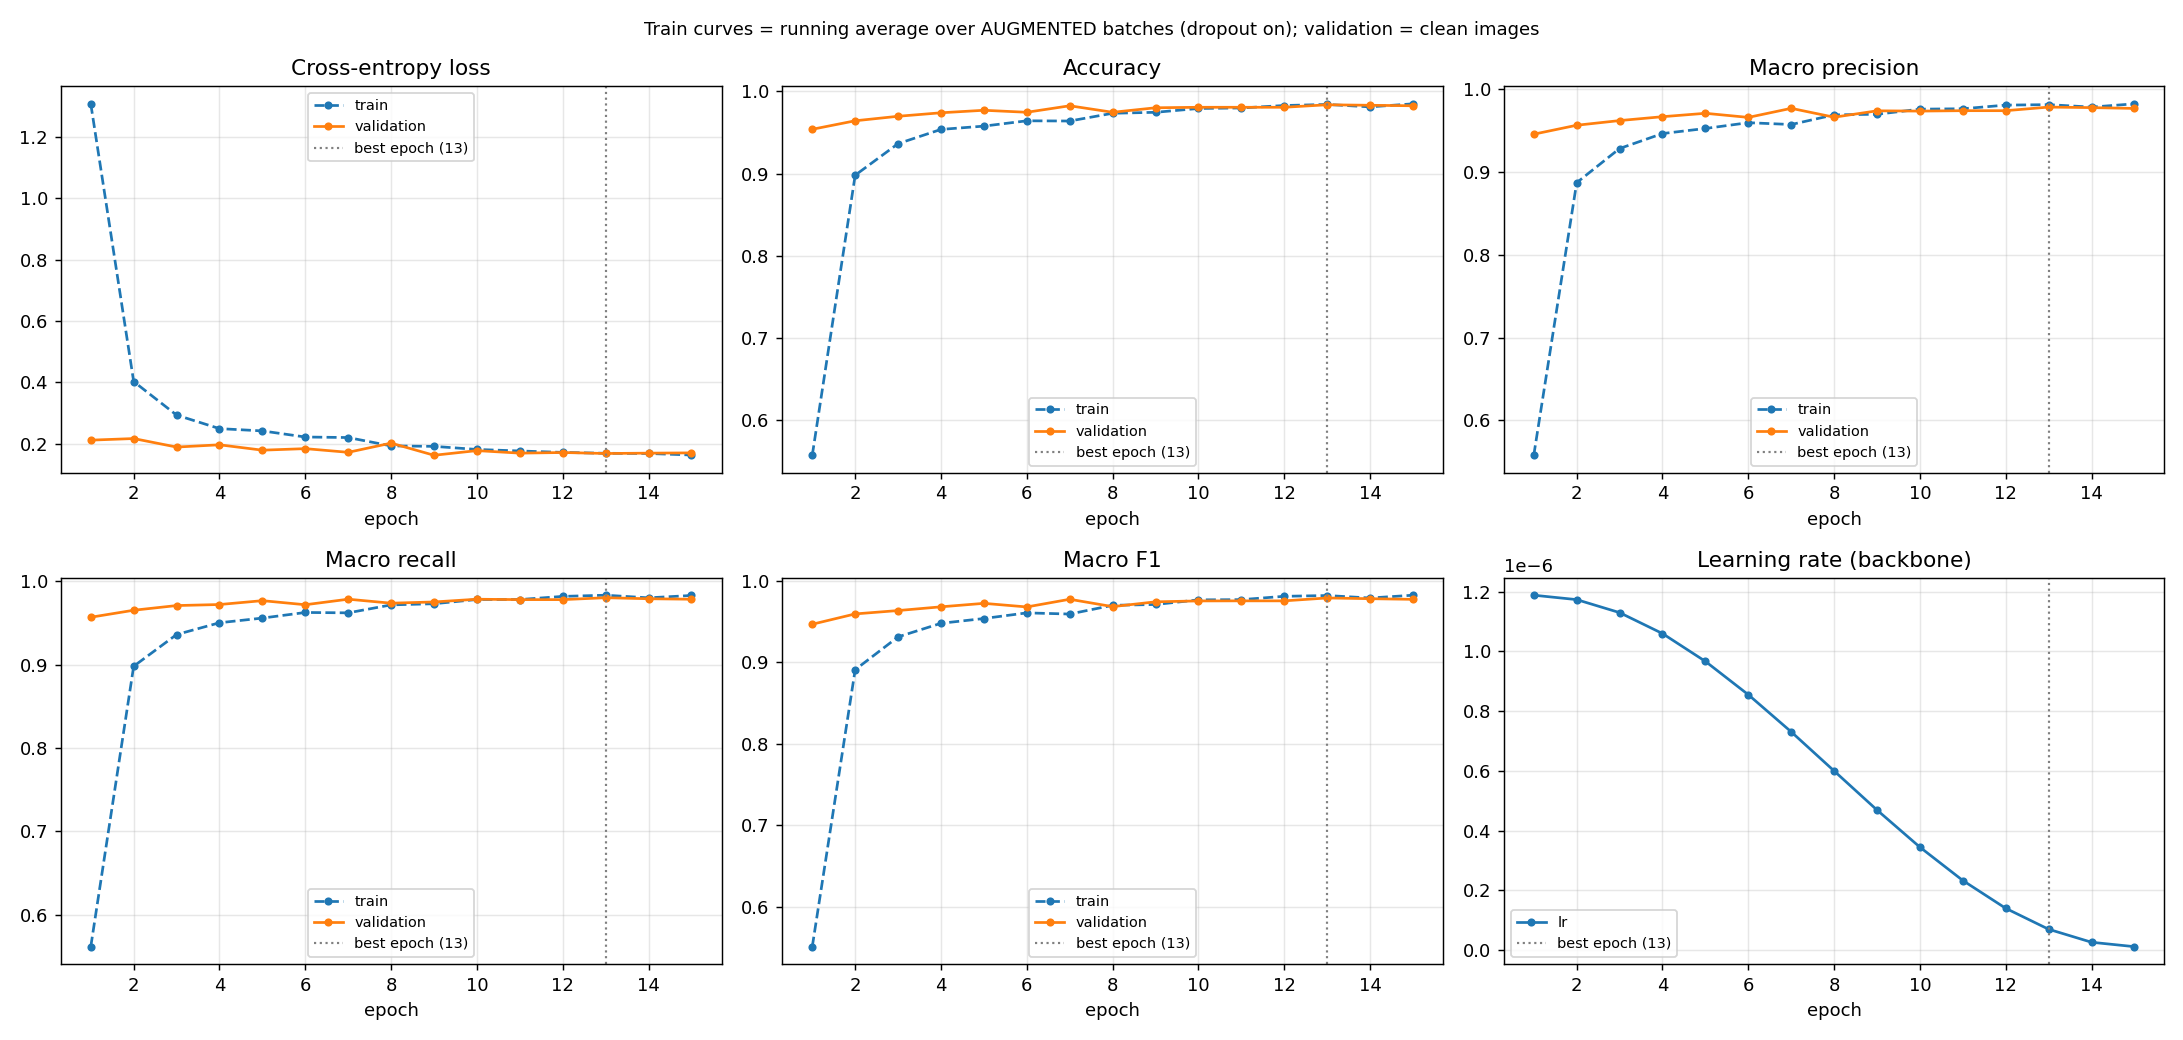


CONFUSION MATRIX - TEST (pooled PlantVillage + PlantDoc)


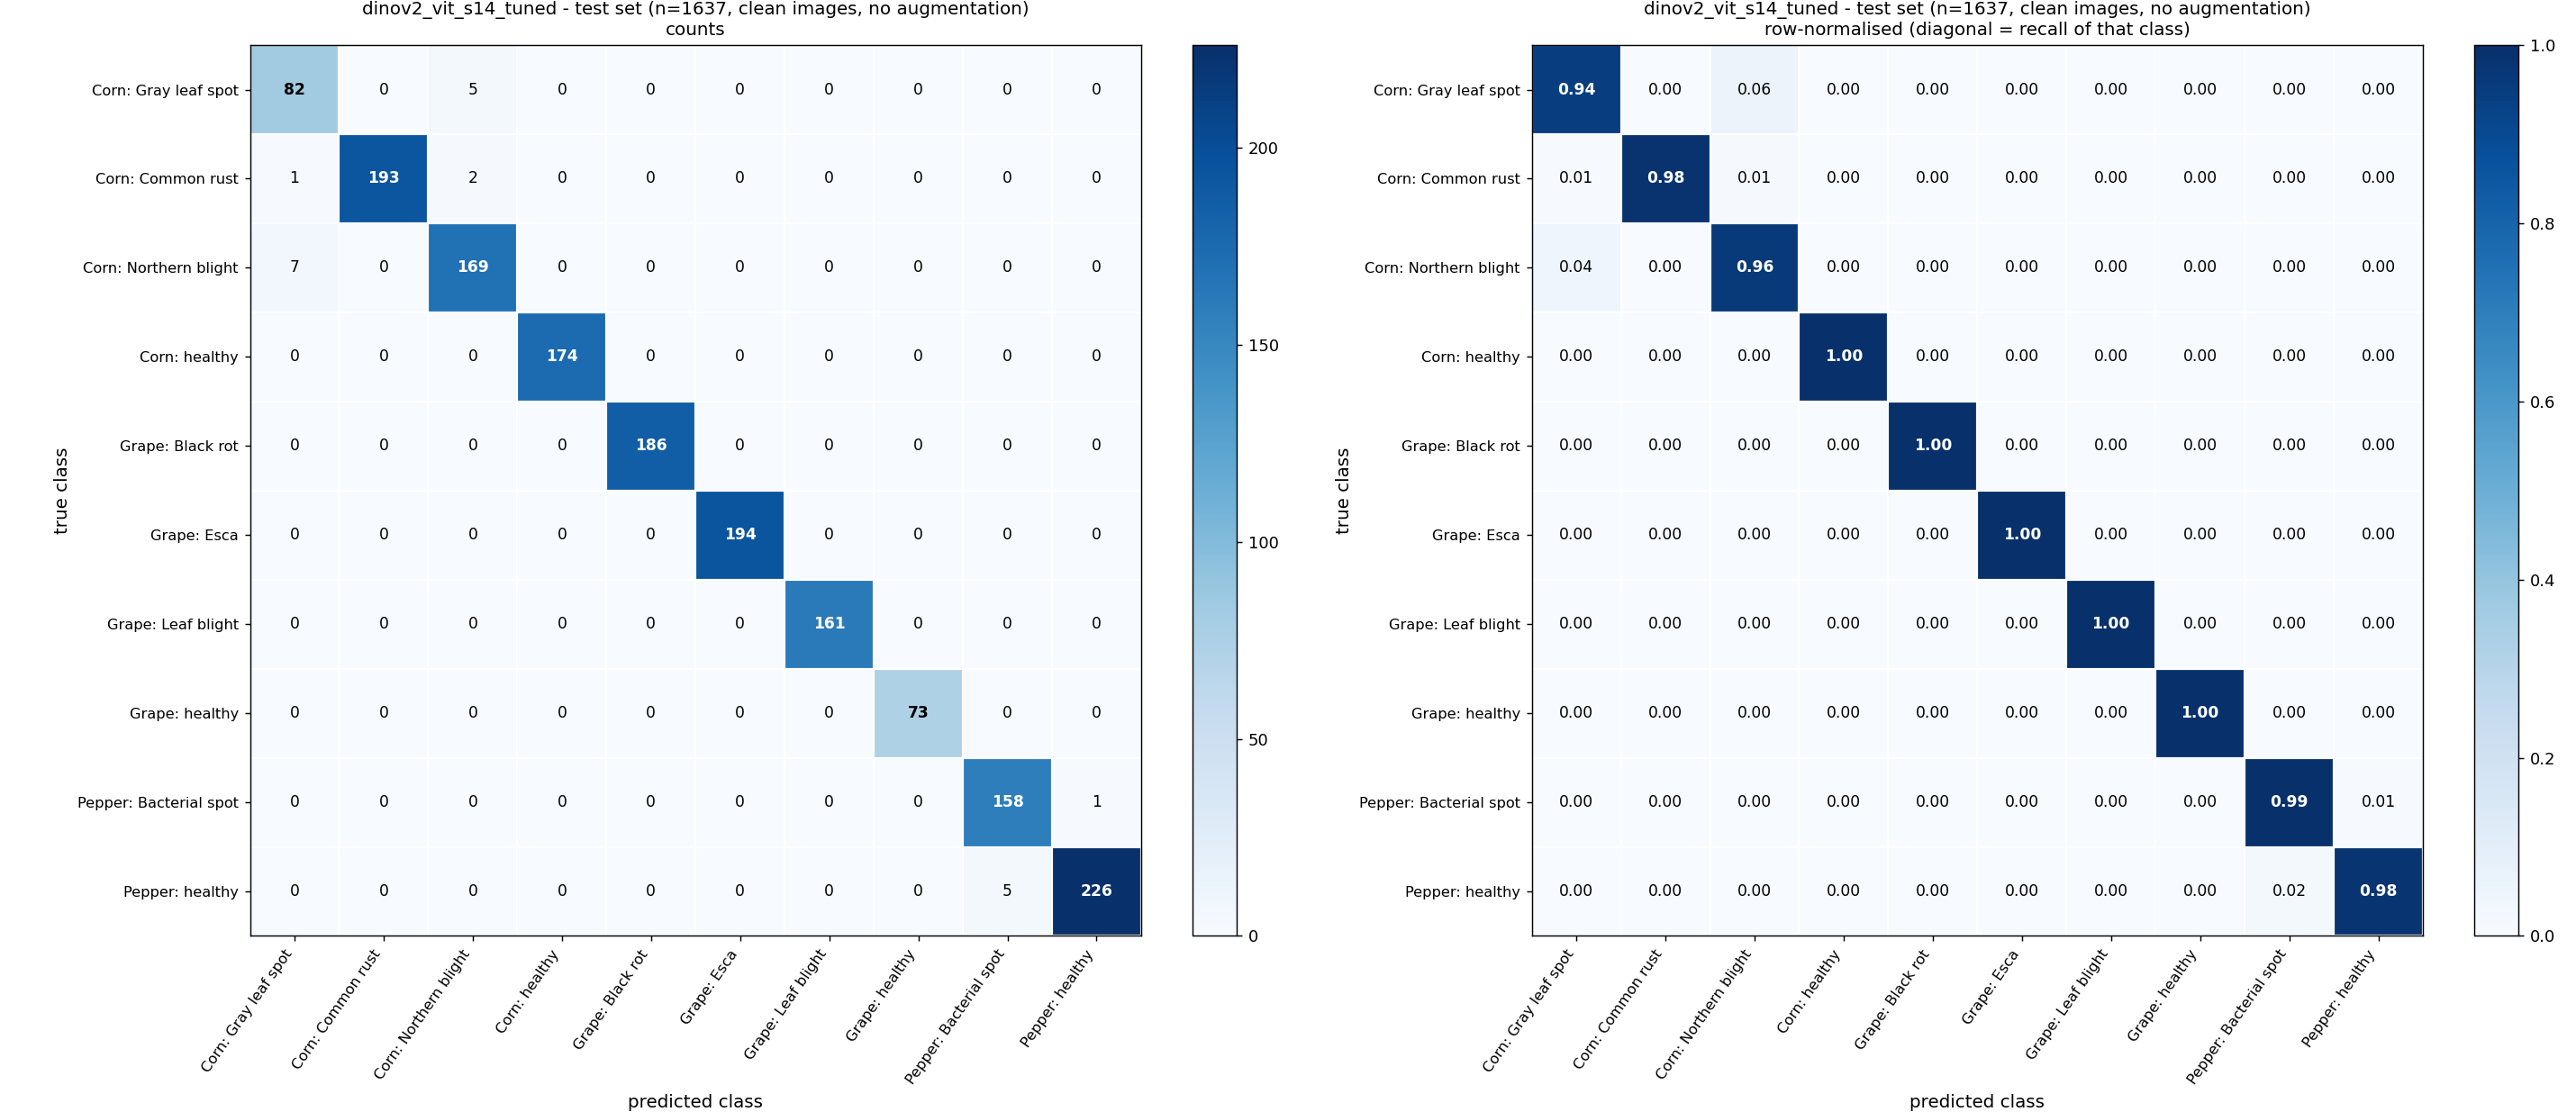


CONFUSION MATRIX - VALIDATION


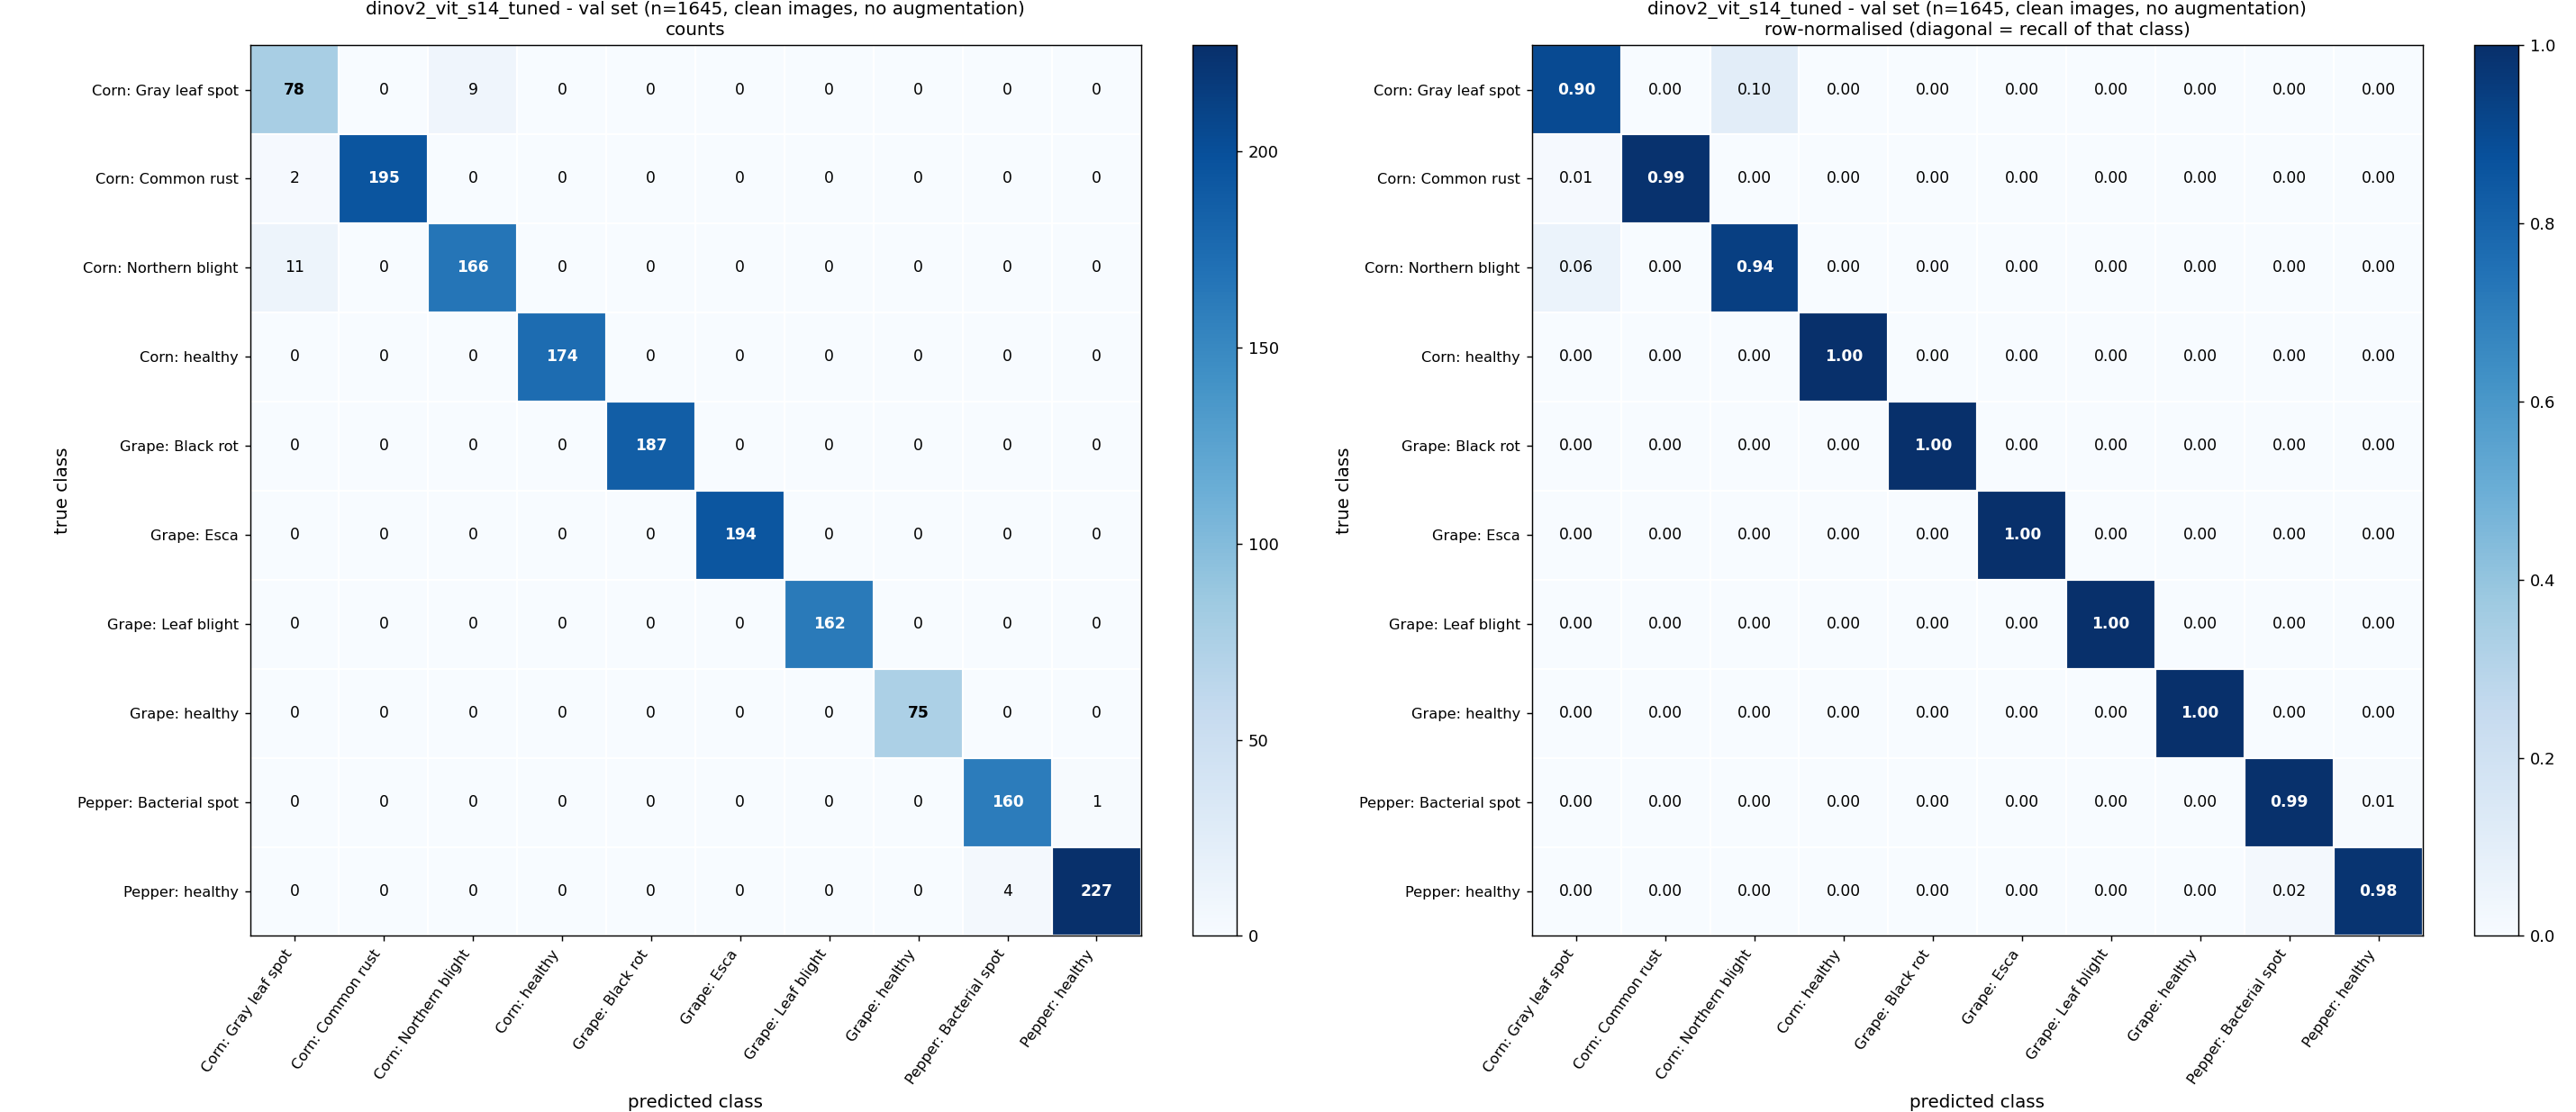


CONFUSION MATRIX - TRAIN


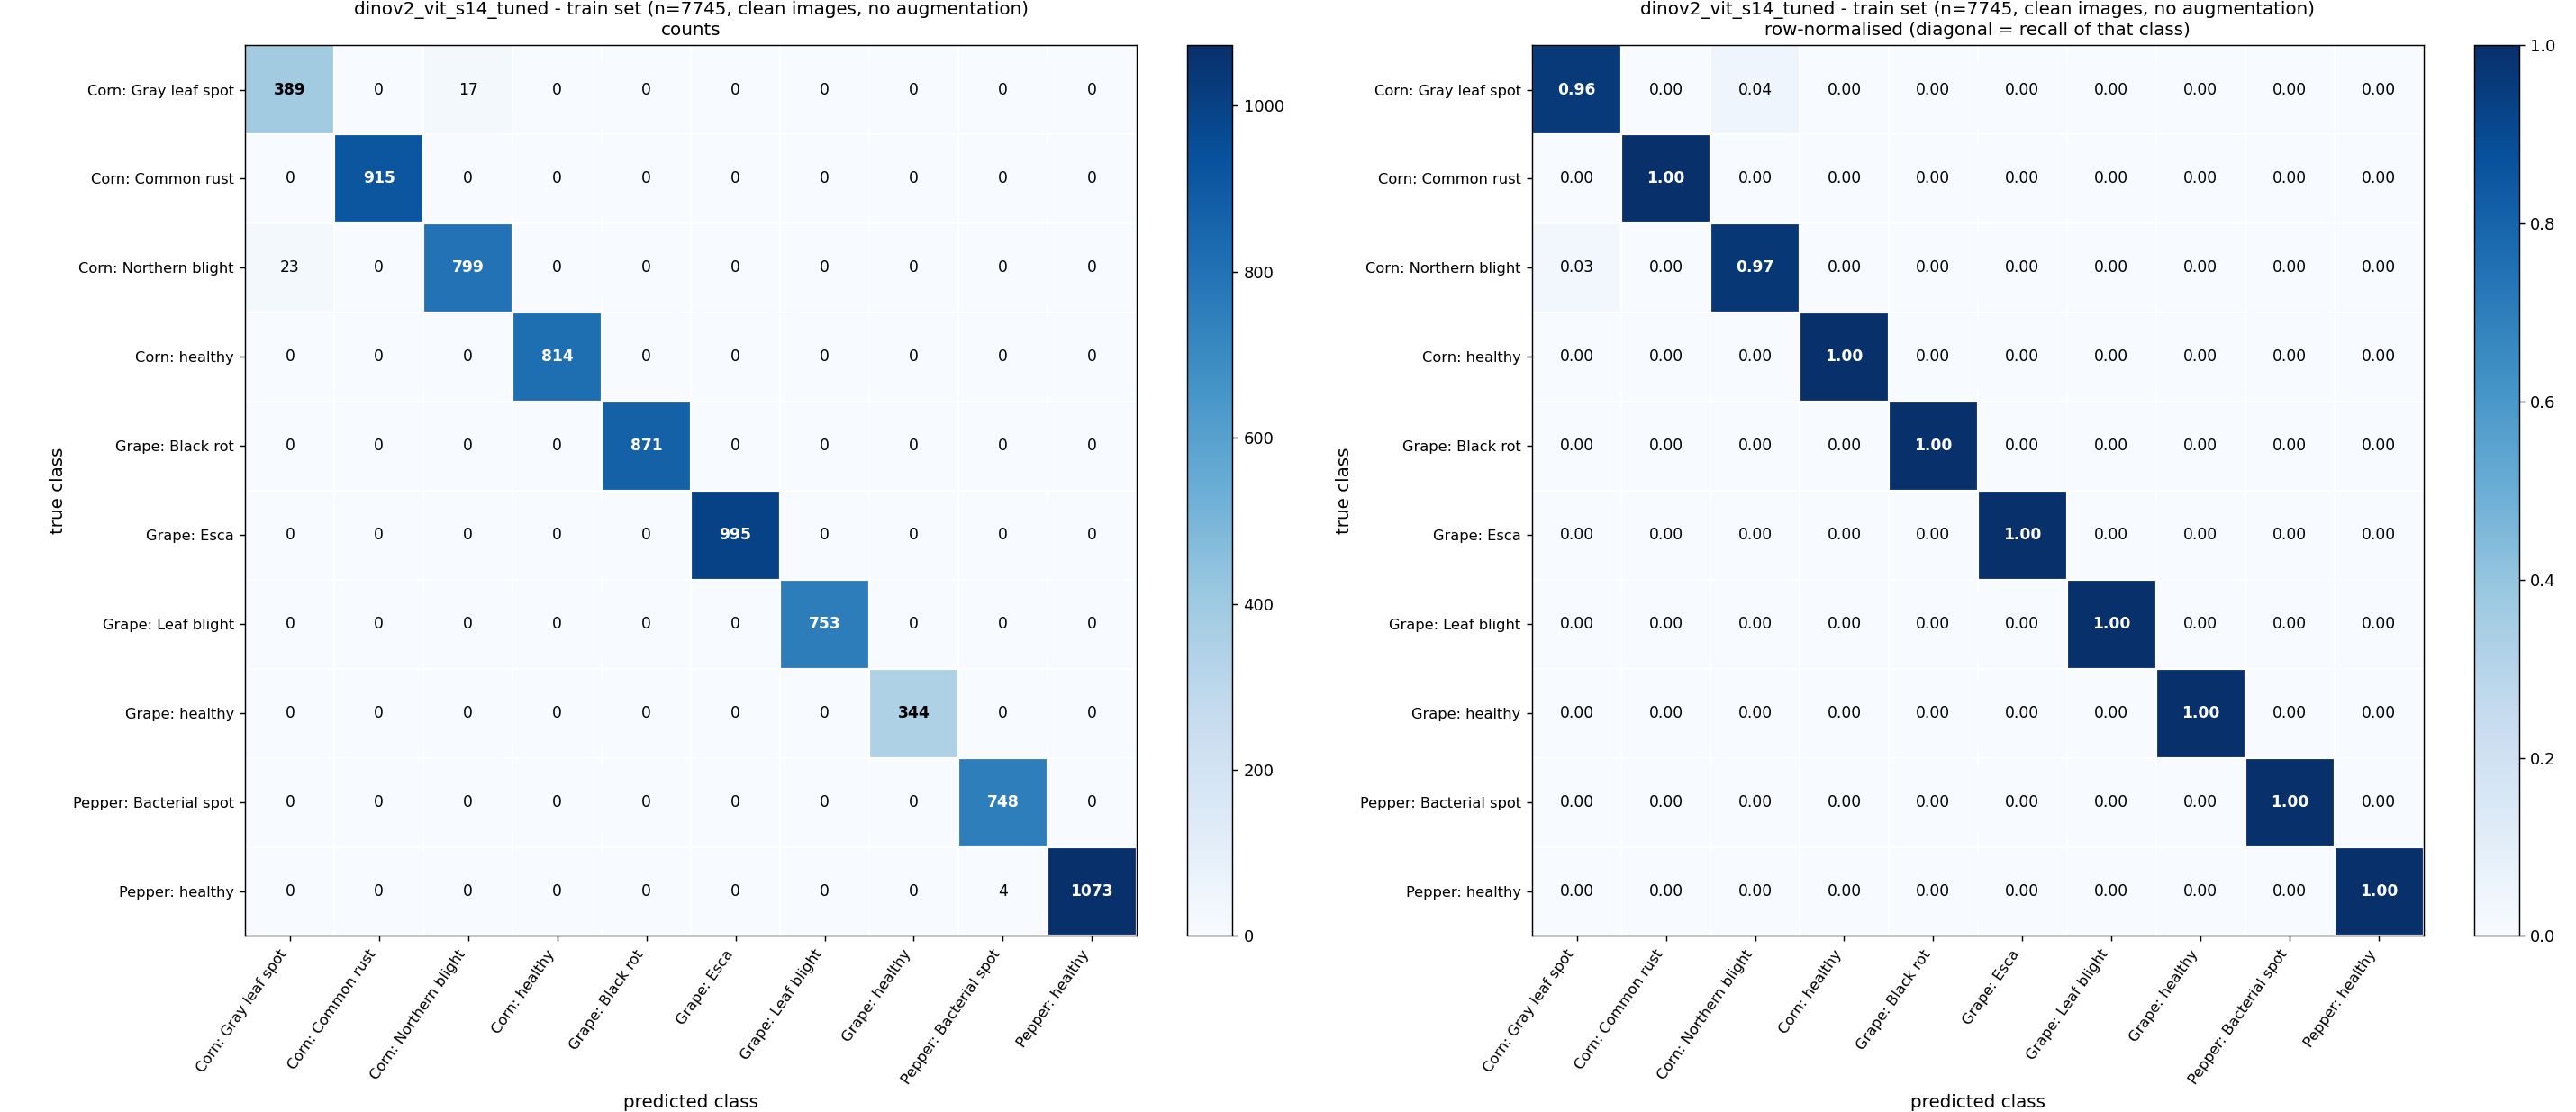


ROC curves - TEST


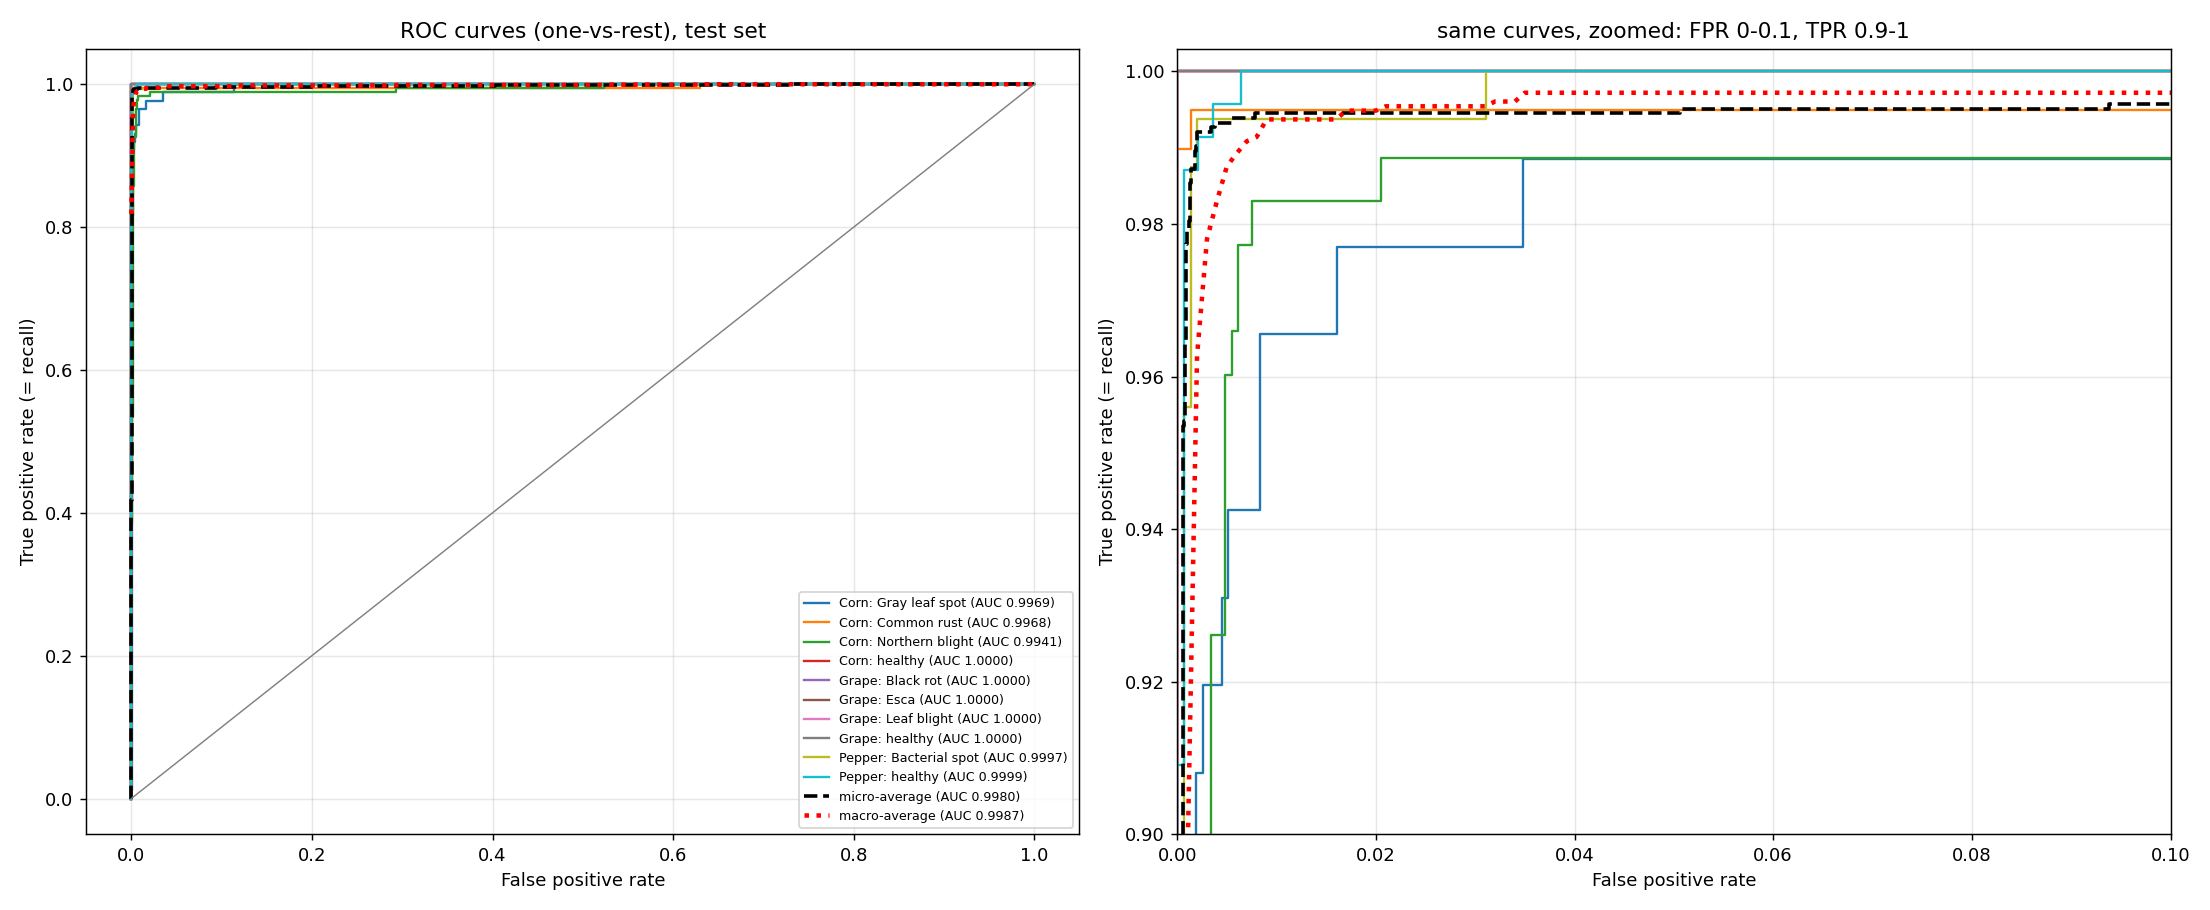


ROC curves - VALIDATION


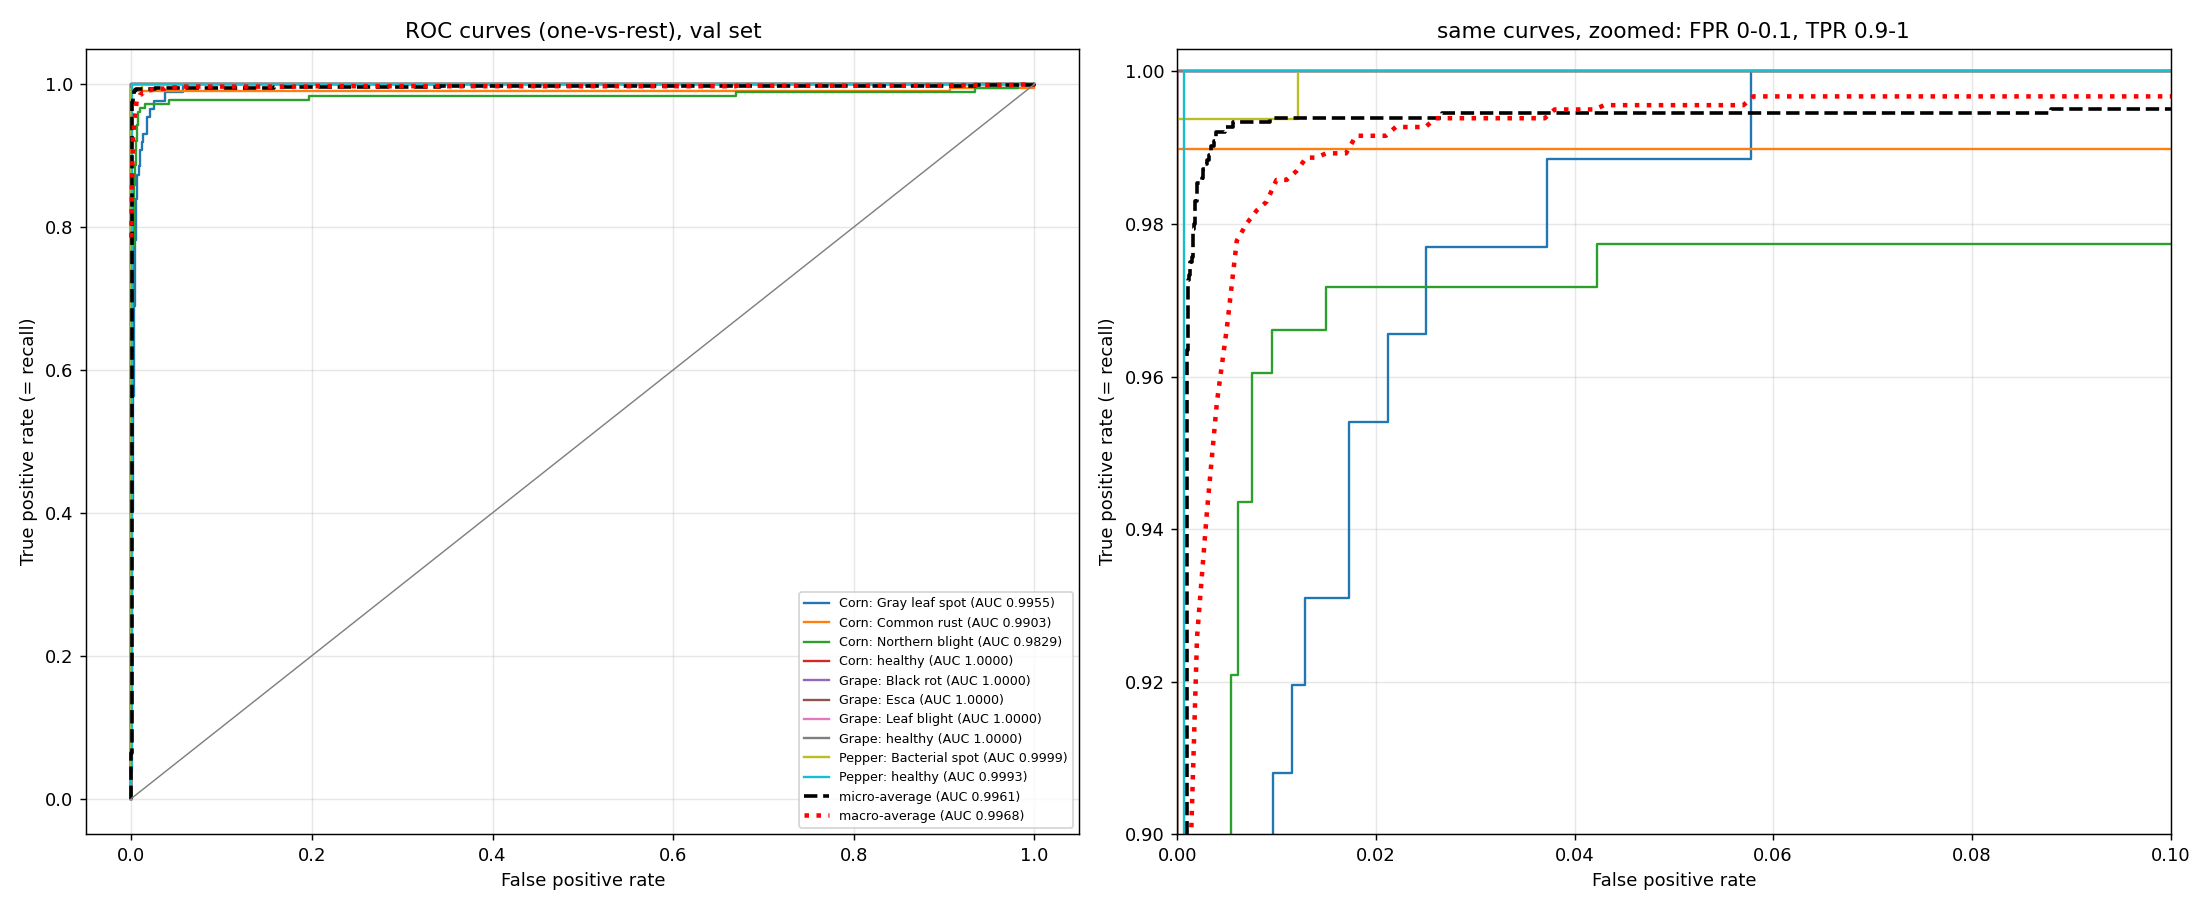


ROC curves - TRAIN


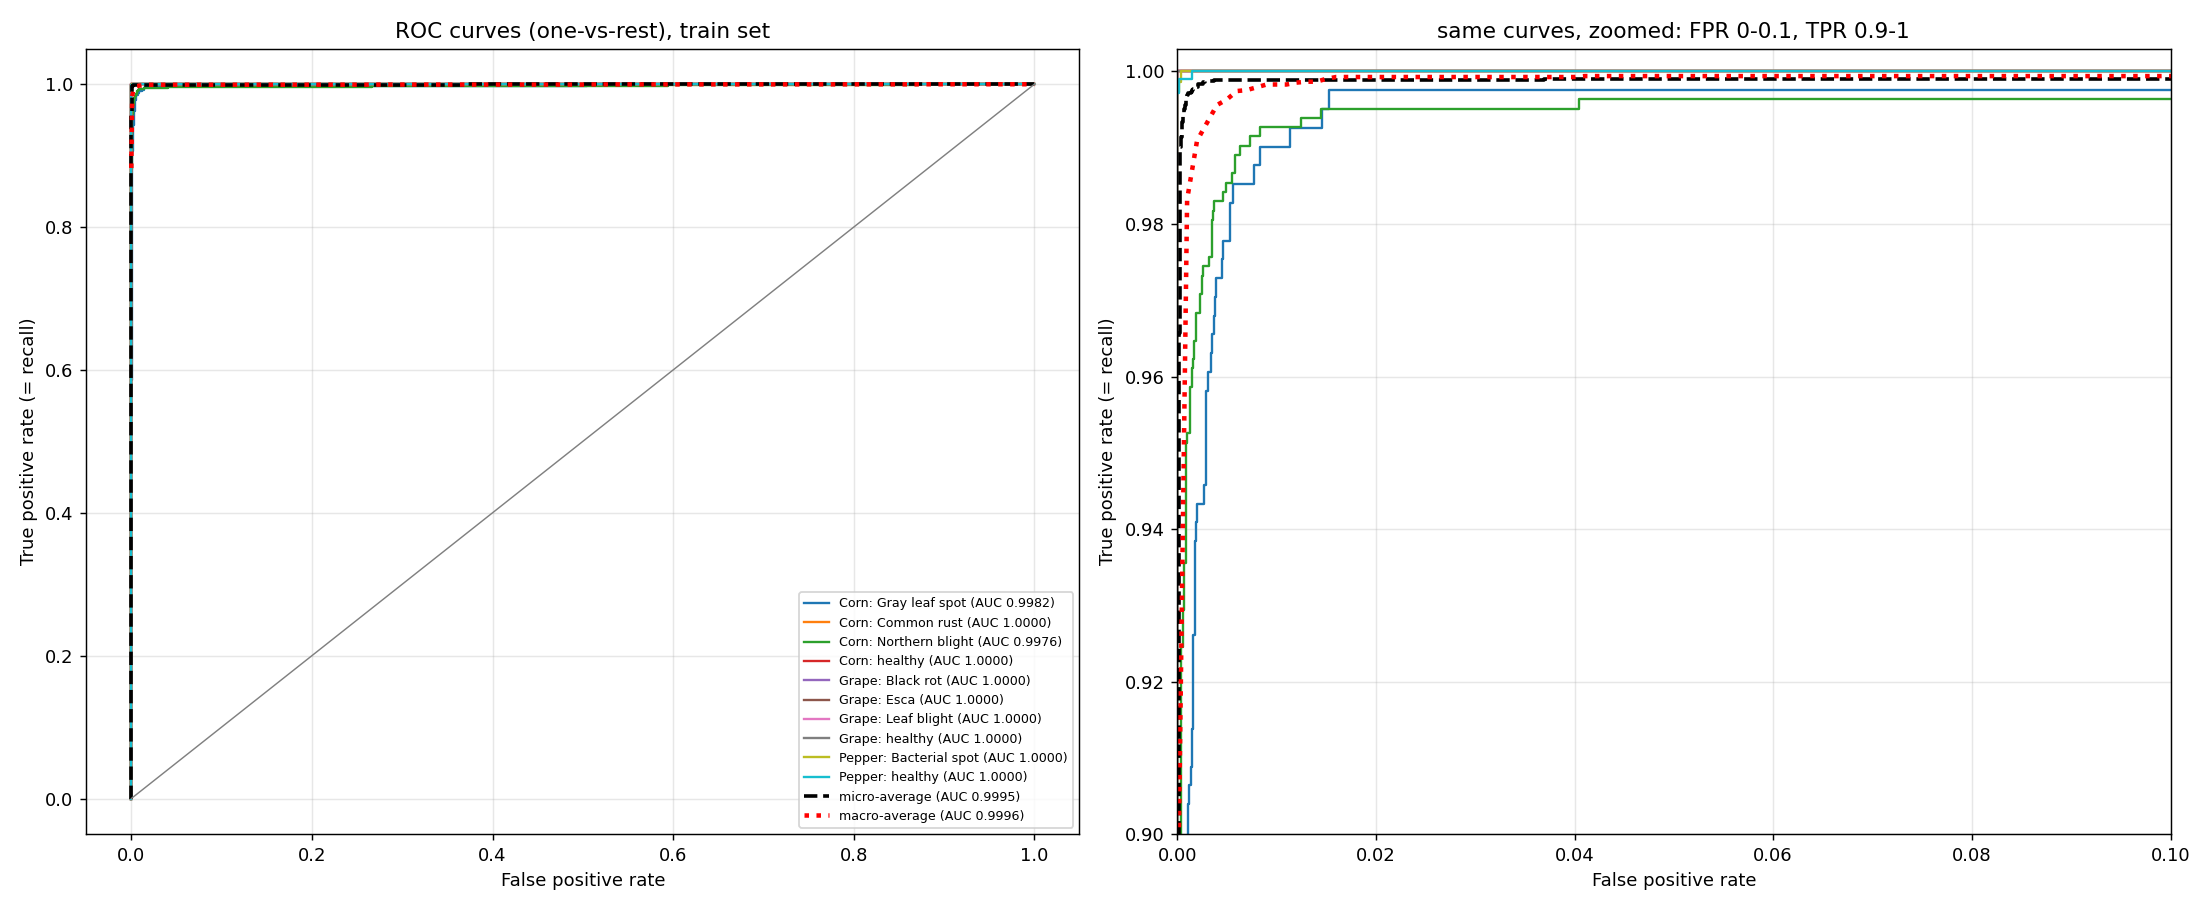


Per-class precision / recall / F1 - TEST


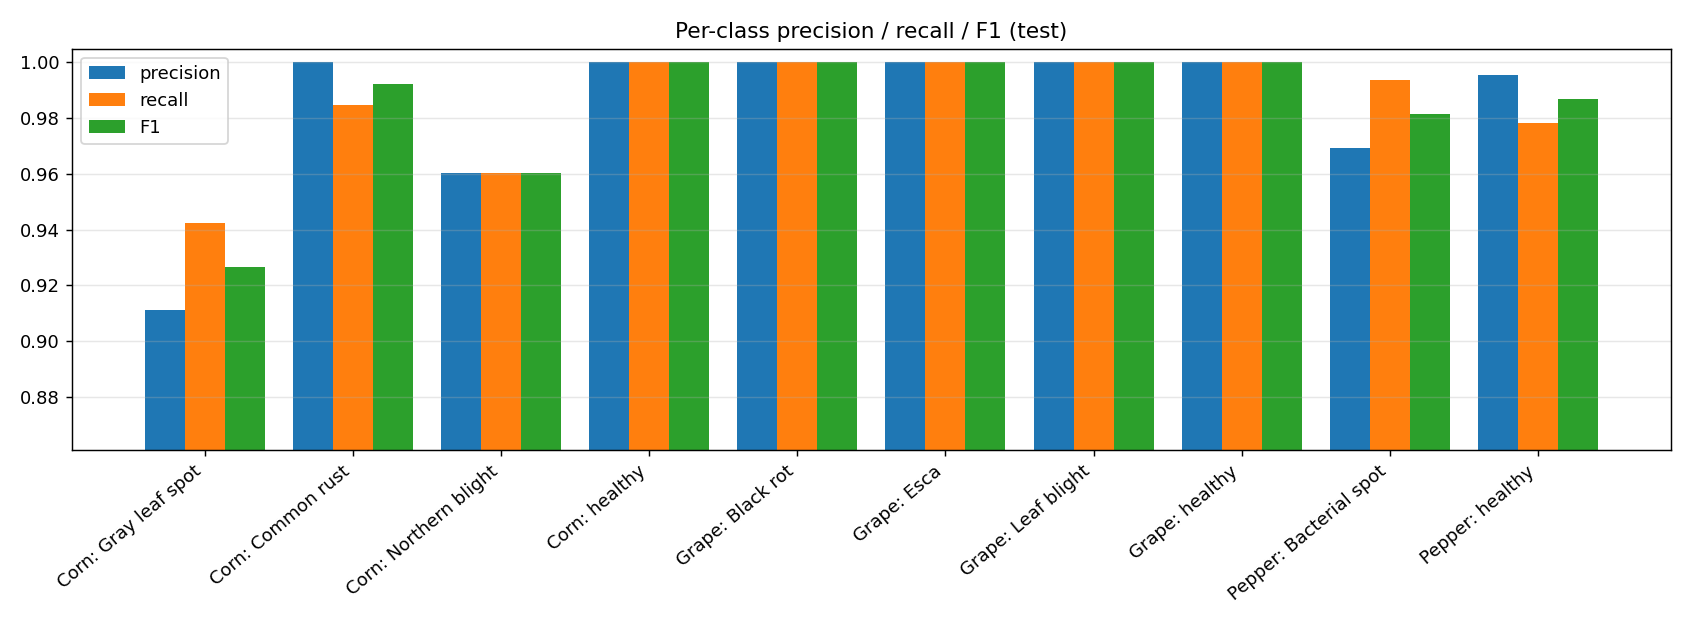


Calibration - TEST


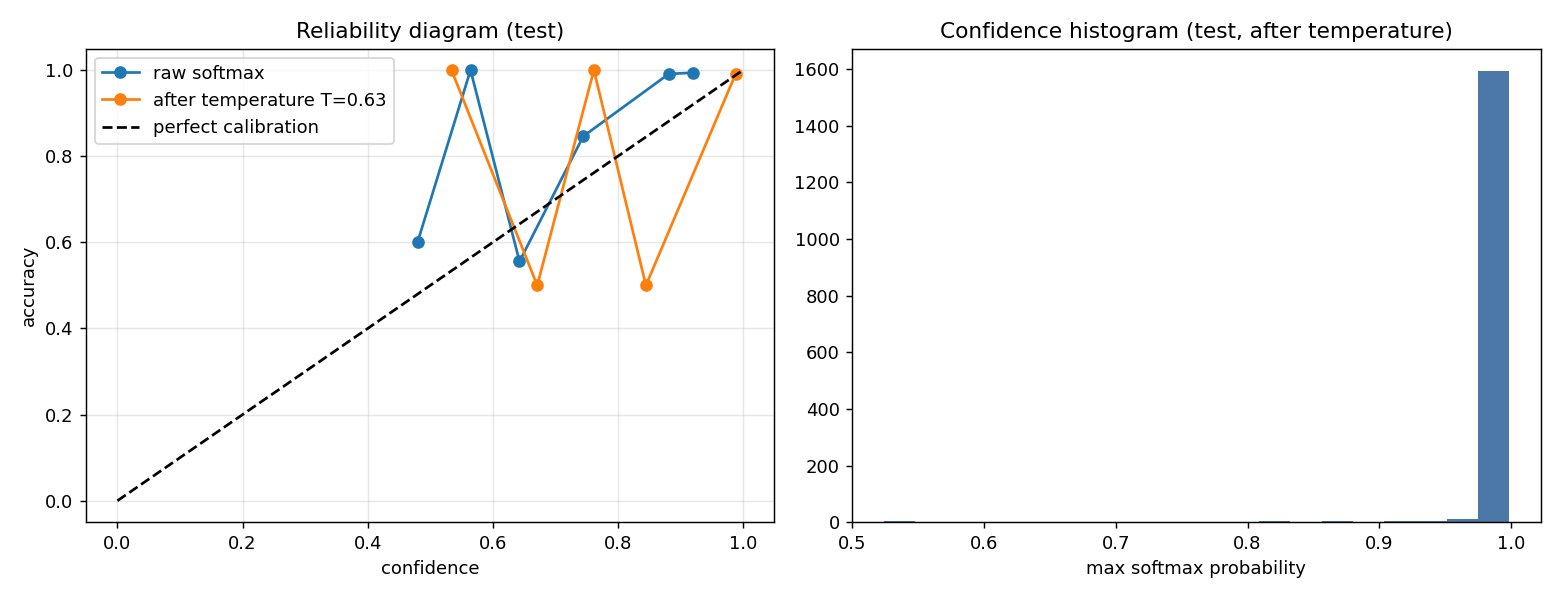


All files saved in /content/drive/MyDrive/plant-disease-v3/results/dinov2_vit_s14_tuned/
['calibration_test.png', 'confusion_matrix_test.csv', 'confusion_matrix_test.png', 'confusion_matrix_train.csv', 'confusion_matrix_train.png', 'confusion_matrix_val.csv', 'confusion_matrix_val.png', 'full_report.txt', 'history.csv', 'metrics_summary.json', 'per_class_metrics.csv', 'per_class_metrics_test.png', 'roc_auc_per_class.csv', 'roc_test.png', 'roc_test_macro.npz', 'roc_train.png', 'roc_train_macro.npz', 'roc_val.png', 'roc_val_macro.npz', 'training_curves.png']


In [ ]:
import os, json, pandas as pd
from IPython.display import Image, display
OUT = f"/content/drive/MyDrive/plant-disease-v3/results/{MODEL}/"
s = json.load(open(OUT + "metrics_summary.json"))
print("Overall metrics (clean images, no augmentation):"); display(pd.DataFrame(s["splits"]).T.round(4))
for title, f in [("TRAIN vs VALIDATION per epoch: loss, accuracy, precision, recall, F1, learning rate", "training_curves.png"),
                 ("CONFUSION MATRIX - TEST (pooled PlantVillage + PlantDoc)", "confusion_matrix_test.png"),
                 ("CONFUSION MATRIX - VALIDATION", "confusion_matrix_val.png"), ("CONFUSION MATRIX - TRAIN", "confusion_matrix_train.png"),
                 ("ROC curves - TEST", "roc_test.png"), ("ROC curves - VALIDATION", "roc_val.png"), ("ROC curves - TRAIN", "roc_train.png"),
                 ("Per-class precision / recall / F1 - TEST", "per_class_metrics_test.png"), ("Calibration - TEST", "calibration_test.png")]:
    print("\n" + title); display(Image(OUT + f))
print("\nAll files saved in", OUT); print(sorted(os.listdir(OUT)))